In [ ]:
# Monte Carlo Simulations test code
'''
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 
import numpy as np



# Function to binarize each signal
def binarize_array(arr, threshold=0.000001): # Values > threshold become 1, others become 0.
    return (arr > threshold).astype(int) 


# load data
movie_path = '/Users/Jeremy/Desktop/Files for visual studio /2026_01_12_Series2_activesomas_filt_traces.csv'
with open(movie_path, 'r') as csv:
     first_line = csv.readline()
     your_data = csv.readlines()

ncol = first_line.count(',') + 1 #count how many ROIs were selected 
print(f"There are {ncol} ROIs in this movie")

data = np.genfromtxt(movie_path, encoding='utf-8-sig', delimiter = ',', usecols=np.arange(0,ncol), dtype='f8')

# 1. Response detection

# binarize data 
binary_data = binarize_array(data)
movie_length = len(binary_data)

# Calculate the difference (discrete derivative)
derivative = np.diff(binary_data[:, 1]) # output will be 0 for no change, 1 for positive change (0 to 1), -1 for negative change (1 to 0), so we will end up with an array size of N-1

# Find where the signal jumps from 0 to 1
event_starts = np.where(derivative == 1)[0] + 1 # np.where returns a tuple, so we use [0] to extract the array of indices. Also need the + 1 because the array is cut off by 1 when performing the derivative 
# Find where the signal drops from 1 to 0
event_ends = np.where(derivative == -1)[0] + 1 # add 1 because later when indexing to splice the event out, the end of the range isn't included

print("Event starts at index:", event_starts) 
print("Event ends at index:  ", event_ends)

# if the event is still active by the end of the recording; handling the edge case. Essentially adding the last index as the end of the event
if len(event_starts) > len(event_ends):
    event_ends = np.append(event_ends, movie_length-1)

# if the event is already going as the recording starts
if len(event_starts) < len(event_ends):
    event_starts = np.insert(event_starts, 0, 0) # at index 0, insert 0


# 2. Randomizing events 

# generating random start times for every event
def generate_shuffled_timeline(event_data_list, total_timeline_length):
    """
    Randomizes both the sequence of events and the gaps between them,
    ensuring zero overlapping to remain biologically valid
    
    event_data_list: A list of 1D numpy arrays, where each array is the raw data of an event.
    total_timeline_length: Total length of the output signal.
    """
    num_events = len(event_data_list)
    
    # Shuffle the sequence of events randomly. Create a shuffled list of indices for events, randomizes the order of all events 
    shuffled_indices = np.random.permutation(num_events)
    
    # Calculate lengths based on the newly shuffled order
    shuffled_lengths = [len(event_data_list[idx]) for idx in shuffled_indices]
    total_event_duration = np.sum(shuffled_lengths)
    
    # Calculate empty space and distribute it randomly into gaps
    total_empty_space = total_timeline_length - total_event_duration
    if total_empty_space < 0:
        raise ValueError("Events are too long to fit into the timeline")
        
    # Pick random split points to divide the dead time
    split_points = np.sort(np.random.choice(total_empty_space + 1, num_events, replace=True))
    
    gaps = np.zeros(num_events + 1, dtype=int)
    gaps[0] = split_points[0]
    gaps[1:-1] = np.diff(split_points)
    gaps[-1] = total_empty_space - split_points[-1]
    
    # 3. Reassemble everything onto a clean canvas
    canvas = np.zeros(total_timeline_length)
    current_position = gaps[0]
    
    for i, orig_idx in enumerate(shuffled_indices):
        event_data = event_data_list[orig_idx]
        event_len = len(event_data)
        
        # Place the event data onto the canvas
        canvas[current_position : current_position + event_len] = event_data
        
        # Advance the pointer past this event and the next random gap
        current_position += event_len + gaps[i + 1]
        
    return canvas

# extracting events from each trace 
def extracting_events(event_starts, event_ends, original_array):
    all_events = []
    for i,_ in enumerate(event_starts):
        event = original_array[event_starts[i]:event_ends[i]]
        all_events.append(event)
    return all_events

all_events = extracting_events(event_starts, event_ends, data[:, 1])

'''
# Run it once to see a fully randomized trial
#shuffled_signal = generate_shuffled_timeline(all_events, movie_length)
#print("Fully randomized timeline:\n", shuffled_signal)
#np.savetxt('test_shuffled_signal.csv', shuffled_signal, delimiter=',')
'''

# 3. Monte Carlo Simulations 

smpCt = 1000 # sample count, aka number of random shuffles 

# pre-alloating memory with floating-point zeros to be filled later 
matrix_zeros = np.zeros((movie_length, smpCt)) # made via rows, columns 

trial = 0 # counter

while trial < 1000:
    shuffled_signal = generate_shuffled_timeline(all_events, movie_length)
    matrix_zeros[:,trial] = shuffled_signal
    trial += 1

np.savetxt('shuffled_signal_1000times_2.csv', matrix_zeros, delimiter=',')
'''


In [53]:
# Monte Carlo Simulations for shuffle control (use this)

import numpy as np
from pathlib import Path 
import glob 

# 1. Define functions needed  
# Function to binarize each signal
def binarize_array(arr, threshold=0.000001): # Values > threshold become 1, others become 0.
    return (arr > threshold).astype(int) 

# generating random start times for every event
def generate_shuffled_timeline(event_data_list, total_timeline_length):
    """
    Randomizes both the sequence of events and the gaps between them,
    ensuring zero overlapping to remain biologically valid
    
    event_data_list: A list of 1D numpy arrays, where each array is the raw data of an event.
    total_timeline_length: Total length of the output signal.
    """
    num_events = len(event_data_list)
    
    # Shuffle the sequence of events randomly. Create a shuffled list of indices for events, randomizes the order of all events 
    shuffled_indices = np.random.permutation(num_events)
    
    # Calculate lengths based on the newly shuffled order
    shuffled_lengths = [len(event_data_list[idx]) for idx in shuffled_indices]
    total_event_duration = np.sum(shuffled_lengths)
    
    # Calculate empty space and distribute it randomly into gaps
    total_empty_space = total_timeline_length - total_event_duration
    if total_empty_space < 0:
        raise ValueError("Events are too long to fit into the timeline")
        
    # Pick random split points to divide the dead time
    split_points = np.sort(np.random.choice(total_empty_space + 1, num_events, replace=True))
    
    gaps = np.zeros(num_events + 1, dtype=int)
    gaps[0] = split_points[0]
    gaps[1:-1] = np.diff(split_points)
    gaps[-1] = total_empty_space - split_points[-1]
    
    # 3. Reassemble everything onto a clean canvas
    canvas = np.zeros(total_timeline_length)
    current_position = gaps[0]
    
    for i, orig_idx in enumerate(shuffled_indices):
        event_data = event_data_list[orig_idx]
        event_len = len(event_data)
        
        # Place the event data onto the canvas
        canvas[current_position : current_position + event_len] = event_data
        
        # Advance the pointer past this event and the next random gap
        current_position += event_len + gaps[i + 1]
        
    return canvas

# extracting events from each trace 
def extracting_events(event_starts, event_ends, original_array):
    all_events = []
    for i,_ in enumerate(event_starts):
        event = original_array[event_starts[i]:event_ends[i]]
        all_events.append(event)
    return all_events

folder_path = '/Users/Jeremy/Desktop/Control IN data/2026_01_27_E15_Gad2/embryo 1/Filtered traces/Soma'

for movie_path in glob.glob(f"{folder_path}/*"): 
    with open(movie_path, 'r') as csv:
        first_line = csv.readline()
        your_data = csv.readlines()

    # 2. load and binarize data
    filt_trace_path = movie_path
    with open(filt_trace_path, 'r') as csv:
        first_line = csv.readline()
        your_data = csv.readlines()

    ncol = first_line.count(',') + 1 #count how many ROIs were selected 
    print(f"There are {ncol} ROIs in this movie")

    data = np.genfromtxt(filt_trace_path, encoding='utf-8-sig', delimiter = ',', usecols=np.arange(0,ncol), dtype='f8')

    neuron = 1
    for row in data.T: 

        # binarize 
        binary_row = binarize_array(row)

        # 3. Response detection

        # Calculate the difference (discrete derivative)
        derivative = np.diff(binary_row) # output will be 0 for no change, 1 for positive change (0 to 1), -1 for negative change (1 to 0), so we will end up with an array size of N-1

        # Find where the signal jumps from 0 to 1
        event_starts = np.where(derivative == 1)[0] + 1 # np.where returns a tuple, so we use [0] to extract the array of indices. Also need the + 1 because the array is cut off by 1 when performing the derivative 
        # Find where the signal drops from 1 to 0
        event_ends = np.where(derivative == -1)[0] + 1 # add 1 because later when indexing to splice the event out, the end of the range isn't included

        print("Event starts at index:", event_starts) 
        print("Event ends at index:  ", event_ends)

        # if the event is still active by the end of the recording; handling the edge case. Essentially adding the last index as the end of the event
        if len(event_starts) > len(event_ends):
            event_ends = np.append(event_ends, movie_length-1)

        # if the event is already going as the recording starts
        if len(event_starts) < len(event_ends):
            event_starts = np.insert(event_starts, 0, 0) # at index 0, insert 0

        # 4. Randomizing events 

        all_events = extracting_events(event_starts, event_ends, row)

        # 5. Monte Carlo Simulations 

        # pre-alloating memory with floating-point zeros to be filled later 
        smpCt = 100 # sample count, aka number of random shuffles 
        movie_length = len(data) # length of movies  
        matrix_zeros = np.zeros((movie_length, smpCt)) # input a tuple, represents (rows, columns)

        trial = 0 # counter

        while trial < smpCt:
            shuffled_signal = generate_shuffled_timeline(all_events, movie_length)
            matrix_zeros[:,trial] = shuffled_signal
            trial += 1
        
        neuron_str = str(neuron)
        file_path = Path(filt_trace_path)
        filename = file_path.name
        filename = filename.removesuffix(".csv")
        filename_MCS = filename + "_shuffledneuron" + neuron_str + '.csv'
        print(filename_MCS)


        np.savetxt(filename_MCS, matrix_zeros, delimiter=',')
        neuron += 1



There are 2 ROIs in this movie
Event starts at index: [4445]
Event ends at index:   [4584]
2026_01_27_Series8_soma_filt_traces_shuffledneuron1.csv
Event starts at index: [4450]
Event ends at index:   [4588]
2026_01_27_Series8_soma_filt_traces_shuffledneuron2.csv
There are 3 ROIs in this movie
Event starts at index: [2064]
Event ends at index:   [2445]
2026_01_27_Series7_soma_filt_traces_shuffledneuron1.csv
Event starts at index: [3877 4224]
Event ends at index:   [4020 4269]
2026_01_27_Series7_soma_filt_traces_shuffledneuron2.csv
Event starts at index: [3909 4024]
Event ends at index:   [3994 4292]
2026_01_27_Series7_soma_filt_traces_shuffledneuron3.csv
There are 7 ROIs in this movie
Event starts at index: [2049 2307]
Event ends at index:   [2147 2357]
2026_01_27_Series6_soma_filt_traces_shuffledneuron1.csv
Event starts at index: [1708 2710 2889 3652]
Event ends at index:   [1785 2744 2959 3712]
2026_01_27_Series6_soma_filt_traces_shuffledneuron2.csv
Event starts at index: [1715 2691 2

In [55]:
# Pairwise Pearson correlation for shuffle control correlations 

import numpy as np
import glob
from scipy import stats
from pathlib import Path
import pandas as pd 

def count_columns(path):
     with open(path, 'r') as csv:
          first_line = csv.readline()
     ncol = first_line.count(',') + 1 
     return ncol

filt_trace_path = '/Users/Jeremy/Desktop/Control IN data/2026_01_27_E15_Gad2/embryo 1/Filtered traces/Soma/2026_01_27_Series6_soma_filt_traces.csv'
shuffled_folder_path = '/Users/Jeremy/Desktop/Control IN data/2026_01_27_E15_Gad2/embryo 1/Shuffled traces/Series 6'

ncol = count_columns(filt_trace_path)
signals = np.genfromtxt(filt_trace_path, encoding='utf-8-sig', delimiter = ',', usecols=np.arange(0,ncol), dtype='f8')
smpCt = 100

cols = ncol*(ncol-1)
matrix_zeros = np.zeros((smpCt, cols)) # tuple is rows, columns 

n = 0 # counter for true signals 
s = 0 # counter for shuffles  
c = 0 # counter for indexing 
headers = []

for shuffle in glob.glob(f"{shuffled_folder_path}/*"): 
     col_count = count_columns(shuffle)
     shuffled_neuron = np.genfromtxt(shuffle, encoding='utf-8-sig', delimiter = ',',usecols=np.arange(0,col_count), dtype='f8')
     i = 0 # counter for amount of shuffles     

     for neuron in signals.T:
          if n == s:
               n += 1
               continue
          else:
               while i < smpCt:
                    shuffle_correlations,_ = stats.pearsonr(shuffled_neuron[:,i], neuron, axis=0) # need to fix?
                    matrix_zeros[i,c] = shuffle_correlations 
                    i += 1
               if n < s:
                    n1 = str(n)
                    n2 = str(s)
                    headers.append(n1+n2)
               else:
                    n1 = str(n)
                    n2 = str(s)
                    headers.append(n2+n1)
               n += 1
               c += 1
               i = 0
     s += 1
     n = 0

# print list for identifying pairs to make sure everything is right  
print(headers)

# combine reciprocal shuffles 

# 1. convert into pandas dataframe, then attach headings to the dataframe 

shuffle_correlations = pd.DataFrame(matrix_zeros)
shuffle_correlations.columns = headers

# 2. assigns numbers based on how many times cumcount() has seen that specific header
counts = shuffle_correlations.columns.to_series().groupby(level=0).cumcount()

# 3. Extract the halves using .values to avoid the iloc error
# We also sort them to ensure the column order matches perfectly before stacking
first_half = shuffle_correlations.iloc[:, (counts == 0).values].sort_index(axis=1)
second_half = shuffle_correlations.iloc[:, (counts == 1).values].sort_index(axis=1)

# 4. concatenate reciprocal columns 
combined_shuffle_correlations = pd.concat([first_half, second_half], ignore_index=True)

print(combined_shuffle_correlations)

# save as csv 

file_path = Path(filt_trace_path)
filename = file_path.name
filename = filename.removesuffix("_activesomas_filt_traces.csv")
filename_corr = filename + "_shufflecorrelations" + '.csv'

combined_shuffle_correlations.to_csv(filename_corr)
# if using numpy instead 
#combined_shuffle_correlations_array = combined_shuffle_correlations.to_numpy() 
#np.savetxt(filename_corr,combined_shuffle_correlations_array,delimiter=',')
print("File saved as", filename_corr)


/opt/homebrew/Caskroom/miniforge/base/lib/python3.12/site-packages/scipy/stats/_stats_py.py:4776: RuntimeWarning: overflow encountered in vecdot
  r = xp.vecdot(xm / normxm, ym / normym, axis=axis)


['01', '02', '03', '04', '05', '06', '01', '12', '13', '14', '15', '16', '02', '12', '23', '24', '25', '26', '03', '13', '23', '34', '35', '36', '04', '14', '24', '34', '45', '46', '05', '15', '25', '35', '45', '56', '06', '16', '26', '36', '46', '56']
           01        02        03        04        05        06        12  \
0   -0.082738 -0.086621 -0.075075  0.150535  0.009206 -0.049036  0.021253   
1   -0.082738 -0.086621 -0.075075 -0.014935 -0.052006 -0.049036  0.381800   
2    0.031396  0.030831 -0.059812 -0.090304 -0.035682 -0.049036  0.329112   
3   -0.082738 -0.086621 -0.075075 -0.111885 -0.095781 -0.049036 -0.058204   
4    0.001981  0.137733 -0.075075  0.214299 -0.017817 -0.049036 -0.058204   
..        ...       ...       ...       ...       ...       ...       ...   
195 -0.041503  0.122310 -0.027108  0.095633  0.581772 -0.034146  0.155838   
196 -0.041503 -0.052863 -0.027108  0.362636 -0.045739  0.243273 -0.070812   
197 -0.041503 -0.052863 -0.027108 -0.047886 -0.045739 

In [56]:
# Pairwise Pearson correlation between real neuron signals (get actual correlations)
import pandas as pd 
import seaborn as sns

folder_path = '/Users/Jeremy/Desktop/Control IN data/2026_01_27_E15_Gad2/embryo 1/Filtered traces/Soma'

for movie_path in glob.glob(f"{folder_path}/*"): 
    with open(movie_path, 'r') as csv:
        first_line = csv.readline()
        your_data = csv.readlines()


    active_neuron_traces = pd.read_csv(movie_path, index_col=None, header=None)

    matrix = active_neuron_traces.corr(method='pearson')
    unstacked = matrix.where(np.triu(np.ones(matrix.shape), k=1).astype(bool)).unstack().dropna()

    actual_corr = pd.DataFrame(unstacked)
    actual_corr.columns = ['actual correlations']
    #print(actual_corr)

    '''
    sns.heatmap(
        matrix, 
        annot=True,         # Show the actual numbers inside the boxes
        cmap='coolwarm',    # Color gradient scheme (blue = negative, red = positive)
        vmin=-1, vmax=1,    # Force the color scale boundaries from -1 to 1
        linewidths=0.5      # Add slight padding between squares
    )
    '''

    file_path = Path(movie_path)
    filename = file_path.name
    filename = filename.removesuffix("_activesomas_filt_traces.csv")
    filename_corr = filename + "_actualcorrelations.csv"
    actual_corr.to_csv(filename_corr)
    print("File saved as", filename_corr)

File saved as 2026_01_27_Series8_soma_filt_traces.csv_actualcorrelations.csv
File saved as 2026_01_27_Series7_soma_filt_traces.csv_actualcorrelations.csv
File saved as 2026_01_27_Series6_soma_filt_traces.csv_actualcorrelations.csv
File saved as 2026_01_27_Series11_soma_filt_traces.csv_actualcorrelations.csv
File saved as 2026_01_27_Series12_soma_filt_traces.csv_actualcorrelations.csv
File saved as 2026_01_27_Series4_soma_filt_traces.csv_actualcorrelations.csv


In [58]:
# Comparing real correlations to shuffle correlations via z-score (this method is per pair). Output is the correlation pairs must be equal or greater than to be significant

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np 

# 1. input paths for actual correlation and shuffle correlation files
actual_corr_path = '/Users/Jeremy/Desktop/Control IN data/2026_01_27_E15_Gad2/embryo 1/Correlations/2026_01_27_Series6_soma_filt_traces.csv_actualcorrelations.csv'
shuffle_corr_path = '/Users/Jeremy/Desktop/Control IN data/2026_01_27_E15_Gad2/embryo 1/Correlations/Shuffle correlations/2026_01_27_Series6_soma_filt_traces.csv_shufflecorrelations.csv'

# 2. call files via pandas 
actual_corr = pd.read_csv(actual_corr_path)
actual_corr.columns = ['pair','neuron','actual correlations']
actual_corr['neuron'] = actual_corr['neuron'].astype(str)
actual_corr['pair'] = actual_corr['pair'].astype(str)
actual_corr['neuron pair'] = actual_corr['neuron']+ actual_corr['pair']
actual_corr = actual_corr.drop(columns=['neuron', 'pair'])
actual_corr = actual_corr[['neuron pair','actual correlations']]
print(actual_corr)


shuffle_correlations = pd.read_csv(shuffle_corr_path,index_col=0)
header = shuffle_correlations.columns.tolist()

# 3. convert shuffle correlations dataframe into numpy array to find standard deviation and mean, and append results to a list
shuffle_correlations_np = shuffle_correlations.to_numpy()

z = 3 # z-score for 99.7% confidence interval (aka 3 SDs or p value of 0.003)
n = 0 # counter 
list = []

for pair in header: 
    std = np.std(shuffle_correlations_np[:,n]) # standard deviation, degrees of freedom is 0
    mean = np.mean(shuffle_correlations_np[:,n]) # mean
    raw_score = z*std + mean # the threshold for a correlation to be signficant    
    print(f"Correlation to be considered significant for pair {pair} is {raw_score}")
    if actual_corr.at[n, 'actual correlations'] > raw_score: #.at[int,column name] allows you to call the value of the row,column specified 
        list.append({'neuron pair':f'# {pair}','actual correlation':actual_corr.at[n, 'actual correlations'],'threshold':raw_score,'significant?':"yes"})
    else:
        list.append({'neuron pair':f'# {pair}','actual correlation':actual_corr.at[n, 'actual correlations'],'threshold':raw_score,'significant?':"no"})
    n+=1

# 4. convert list to pandas dataframe for saving 
dataframe = pd.DataFrame(list)
print(dataframe)
dataframe.astype({'neuron pair': str, 'actual correlation': float,'threshold': float,'significant?':str})


file_path = Path(actual_corr_path)
filename = file_path.name
filename = filename.removesuffix("_actualcorrelations.csv")
filename_corr = filename + "_sig_correlations.csv"
dataframe.to_csv(filename_corr)
print("File saved as", filename_corr)


#sns.violinplot(data = shuffle_correlations)


   neuron pair  actual correlations
0           01            -0.045739
1           02            -0.047886
2           12             0.906929
3           03             0.718562
4           13             0.020619
5           23             0.007107
6           04            -0.061852
7           14            -0.042821
8           24             0.004834
9           34            -0.057838
10          05             0.289692
11          15            -0.070928
12          25            -0.074257
13          35             0.564634
14          45             0.279361
15          06            -0.027108
16          16            -0.036312
17          26            -0.038017
18          36            -0.032949
19          46            -0.049105
20          56            -0.042037
Correlation to be considered significant for pair 01 is 0.3280879771151452
Correlation to be considered significant for pair 02 is 0.29546966986657136
Correlation to be considered significant for pair 03 is 0

The percentage of E13 pairs that are significant is 48.97959183673469
The percentage of E14 pairs that are significant is 18.152866242038215
The percentage of E15 pairs that are significant is 23.28042328042328
The percentage of E16 pairs that are significant is 17.981072555205046
The percentage of E17 pairs that are significant is 8.195020746887966
The percentage of E18 pairs that are significant is 11.652794292508919
E13 n = 24
E14 n = 57
E15 n = 220
E16 n = 57
E17 n = 79
E18 n = 98
Statistic: 726.0
P-value: 1.7413872217636603e-11
Conclusion: Reject the null hypothesis; the means are significantly different.


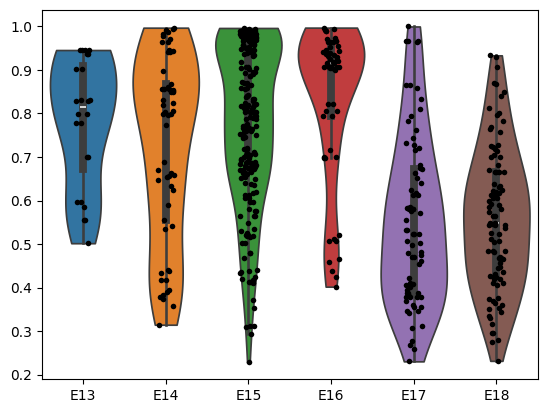

In [80]:
# Plotting correlations 

import pandas as pd 
import seaborn as sns
import numpy as np 
import os 

# define functions 

def concat_csv(file_path):
    all_files= glob.glob(os.path.join(file_path, "*.csv"))
    df_list = [pd.read_csv(filename, index_col=None, header=0) for filename in all_files]
    combined_df = pd.concat(df_list, axis=0, ignore_index=True)
    return combined_df

def isolate_sig_corr(data):
    # isolate the actual correlations and threshold for significant correlations 
    correlations = data.iloc[:,2:4]
    correlations = correlations.to_numpy()

    # count how many rows there are and convert pandas dataframe into numpy array  
    rows = len(correlations)
    sig_cor = np.array([])
    n = 0 #counter for while loop 

    # append significant correlations into a numpy array 
    while n < rows:
        if correlations[n,0] > correlations[n,1]:
            sig_cor = np.append(sig_cor,[correlations[n,0]])
        n+=1
    return sig_cor

def percent_sigcor_pairs(data):
    total_pairs = len(data)
    count = (data['significant?'] == 'yes').sum()
    percentage_sigcor_pairs = count/total_pairs*100
    return percentage_sigcor_pairs


# file paths to correlations 
E13a = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_05_04_E13_Gad2/Correlations/Sig correlations')
E13b = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_06_17_E13_Gad2/embryo 1/Correlations/Sig correlations')
E13c = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_06_17_E13_Gad2/embryo 2/Correlations/Sig correlations')
E13d = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_06_25_E13_Gad2/Correlations/Sig correlations')
combined_df_E13 = pd.concat([E13a,E13b, E13c,E13d], axis=0, ignore_index=True)
E13_corr = isolate_sig_corr(combined_df_E13)
E13_corr = pd.DataFrame(E13_corr)
E13_corr.columns=['E13']

E14a = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_01_12_E14_Gad2/Correlations/Sig correlations')
E14b = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_02_04_E14_Gad2/Correlations/Sig correlations')
E14c = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_02_12_E14_Gad2/Correlations/Sig correlations')
E14d = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_07_10_E14_Gad2/Correlations/Sig correlations')
combined_df_E14 = pd.concat([E14a, E14c, E14d], axis=0, ignore_index=True)
E14_corr = isolate_sig_corr(combined_df_E14)
E14_corr = pd.DataFrame(E14_corr)
E14_corr.columns=['E14']

E15a = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_01_27_E15_Gad2/embryo 1/Correlations/sig correlations')
E15b = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_01_27_E15_Gad2/embryo 2/Correlations/Sig correlations')
E15c = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_01_28_E15_Gad2/Correlations/Sig correlations')
E15d = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_03_29_E15_Gad2/Correlations/Sig correlations')
combined_df_E15 = pd.concat([E15a,E15b, E15c, E15d], axis=0, ignore_index=True)
E15_corr = isolate_sig_corr(combined_df_E15)
E15_corr = pd.DataFrame(E15_corr)
E15_corr.columns=['E15']

E16a = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_01_13_E16_Gad2/Correlations/Sig correlations')
E16b = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_01_30_E16_Gad2/Correlations/Sig correlations')
E16c = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_03_02_E16_Gad2/Correlations/Sig correlations')
E16d = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_07_12_E16_Gad2/Correlations/Sig correlations')
combined_df_E16 = pd.concat([E16a,E16b, E16c, E16d], axis=0, ignore_index=True)
E16_corr = isolate_sig_corr(combined_df_E16)
E16_corr = pd.DataFrame(E16_corr)
E16_corr.columns=['E16']

E17a = concat_csv('/Users/Jeremy/Desktop/Control IN data/2025_02_19_E17_Gad2/Correlations/Sig correlations')
E17b = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_02_02_E17_Gad2/Correlations/Sig correlations')
E17c = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_03_05_E17_Gad2/embryo 1/Correlations/Sig correlations')
E17d = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_03_05_E17_Gad2/embryo 2/Correlations/Sig correlations')
combined_df_E17 = pd.concat([E17a,E17b, E17c, E17d], axis=0, ignore_index=True)
E17_corr = isolate_sig_corr(combined_df_E17)
E17_corr = pd.DataFrame(E17_corr)
E17_corr.columns=['E17']

E18a = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_01_15_E18_Gad2/Embryo 1/Correlations/Sig correlations')
E18b = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_01_15_E18_Gad2/Embryo 2/Correlations/Sig correlations')
E18c = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_02_09_E18_Gad2/embryo 1/Correlations/Sig correlations')
E18d = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_02_09_E18_Gad2/embryo 2/Correlations/Sig correlations')
combined_df_E18 = pd.concat([E18a,E18b, E18c, E18d], axis=0, ignore_index=True)
E18_corr = isolate_sig_corr(combined_df_E18)
E18_corr = pd.DataFrame(E18_corr)
E18_corr.columns=['E18']

all_sig_correlations = pd.concat([E13_corr, E14_corr,E15_corr, E16_corr, E17_corr, E18_corr], axis=1) 


sns.violinplot(data = all_sig_correlations,cut=0)
sns.stripplot(all_sig_correlations, color = 'black', size=4, jitter = True)

#vectorizing the matplotlib figure into a EPS  
#plt.savefig("Control_correlations.eps", format="eps")

#percentages
E13_percent = percent_sigcor_pairs(combined_df_E13)
print("The percentage of E13 pairs that are significant is",E13_percent)
E14_percent = percent_sigcor_pairs(combined_df_E14)
print("The percentage of E14 pairs that are significant is",E14_percent)
E15_percent = percent_sigcor_pairs(combined_df_E15)
print("The percentage of E15 pairs that are significant is",E15_percent)
E16_percent = percent_sigcor_pairs(combined_df_E16)
print("The percentage of E16 pairs that are significant is",E16_percent)
E17_percent = percent_sigcor_pairs(combined_df_E17)
print("The percentage of E17 pairs that are significant is",E17_percent)
E18_percent = percent_sigcor_pairs(combined_df_E18)
print("The percentage of E18 pairs that are significant is",E18_percent)

# n number 

E13_n = len(E13_corr)
print("E13 n =",E13_n)
E14_n = len(E14_corr)
print("E14 n =",E14_n)
E15_n = len(E15_corr)
print("E15 n =",E15_n)
E16_n = len(E16_corr)
print("E16 n =",E16_n)
E17_n = len(E17_corr)
print("E17 n =",E17_n)
E18_n = len(E18_corr)
print("E18 n =",E18_n)

# Wilcoxon rank-sum test aka Mann-Whitney test to see if correlations are signficant between days 
from scipy.stats.mstats import mannwhitneyu

statistic, p_value = mannwhitneyu(E17_corr, E16_corr) # don't think we need to use the continuity correction 


alpha = 0.05/5 # E13-18 bonferonni correction 

print(f"Statistic: {statistic}")
print(f"P-value: {p_value}")

if p_value < alpha:
    print("Conclusion: Reject the null hypothesis; the means are significantly different.")
else:
    print("Conclusion: Fail to reject the null hypothesis; there is no significant difference.")


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


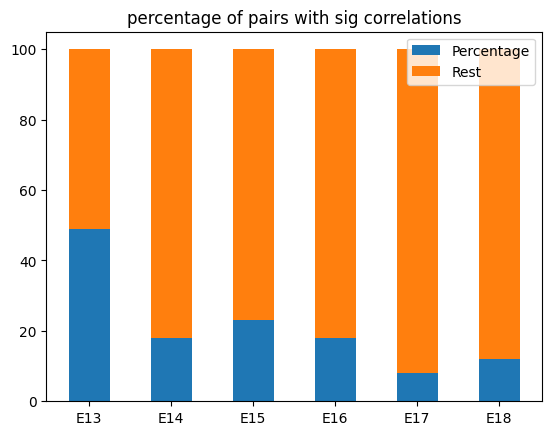

In [73]:
# plotting percentages as bars 
import pandas as pd 
import matplotlib.pyplot as plt

days = ("E13","E14","E15","E16","E17","E18")

percentages = {
    "Percentage": np.array([49,18,23,18,8,12]),
    "Rest": np.array([51,82,77,82,92,88]),
}

fig, ax = plt.subplots()
bottom = np.zeros(6)

for boolean, percent in percentages.items():
    p = ax.bar(days, percent, width =0.5, label=boolean, bottom=bottom)
    bottom += percent

ax.set_title("percentage of pairs with sig correlations")
ax.legend(loc="upper right")

#vectorizing the matplotlib figure into a EPS  
plt.savefig("Control_correlation_percentages.eps", format="eps")

# Display the plot
plt.show()





/opt/homebrew/Caskroom/miniforge/base/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: 

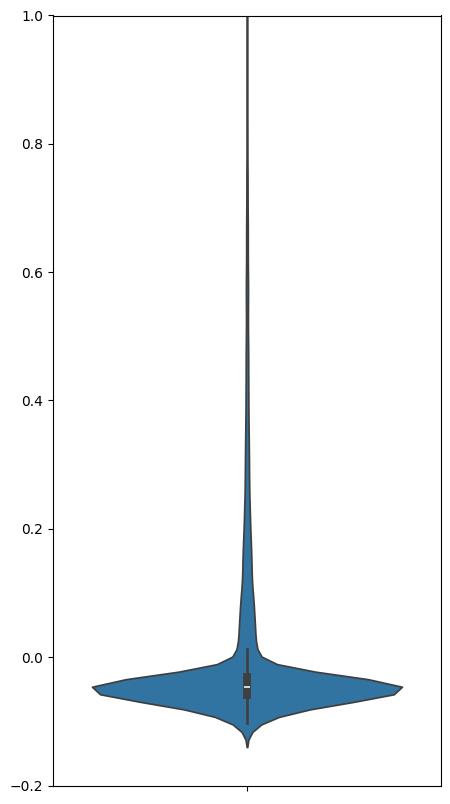

In [76]:
#plotting all the shuffle controls 
import pandas as pd 
import seaborn as sns
import numpy as np  
import os 
import matplotlib.pyplot as plt 

def concat_csv(file_path):
    all_files= glob.glob(os.path.join(file_path, "*.csv"))
    df_list = [pd.read_csv(filename, index_col=0, header=0) for filename in all_files]
    combined_df = pd.concat(df_list, axis=0, ignore_index=True)
    array = combined_df.to_numpy()
    unravelled_array = array.ravel()
    unravelled_array = unravelled_array[~np.isnan(unravelled_array)]
    return unravelled_array

E13_shuffle1 = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_05_04_E13_Gad2/Correlations/Shuffle correlations')
E13_shuffle2 = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_06_17_E13_Gad2/embryo 1/Correlations/Shuffle correlations')
combined_shuffles_E13 = np.concatenate((E13_shuffle1,E13_shuffle2))


E14_shuffle1 = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_01_12_E14_Gad2/Correlations/Shuffle correlations')
E14_shuffle2 = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_07_10_E14_Gad2/Correlations/Shuffle correlations')
combined_shuffles_E14 = np.concatenate((E14_shuffle1,E14_shuffle2))

E15_shuffle1 = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_01_27_E15_Gad2/embryo 1/Correlations/Shuffle correlations')
E15_shuffle2 = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_01_27_E15_Gad2/embryo 2/Correlations/Shuffle correlations')
combined_shuffles_E15 = np.concatenate((E15_shuffle1,E15_shuffle2))

E16_shuffle1 = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_01_30_E16_Gad2/Correlations/Shuffle correlations')
E16_shuffle2 = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_07_12_E16_Gad2/Correlations/Shuffle correlations')
combined_shuffles_E16 = np.concatenate((E16_shuffle1,E16_shuffle2))

E17_shuffle1 = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_02_02_E17_Gad2/Correlations/Shuffle correlations')
E17_shuffle2 = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_03_05_E17_Gad2/embryo 1/Correlations/Shuffle correlations')
combined_shuffles_E17 = np.concatenate((E17_shuffle1,E17_shuffle2))

E18_shuffle1 = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_02_09_E18_Gad2/embryo 1/Correlations/Shuffle correlations')
E18_shuffle2 = concat_csv('/Users/Jeremy/Desktop/Control IN data/2026_02_09_E18_Gad2/embryo 2/Correlations/Shuffle correlations')
combined_shuffles_E18 = np.concatenate((E18_shuffle1,E18_shuffle2))


#shuffled_data = np.concatenate((combined_shuffles_E13, combined_shuffles_E14,combined_shuffles_E15, combined_shuffles_E16, combined_shuffles_E17, combined_shuffles_E18))
shuffled_data = np.concatenate((E13_shuffle1, E14_shuffle1,E15_shuffle1, E16_shuffle1, E17_shuffle1, E18_shuffle1))

plt.figure(figsize=(5, 10))
sns.violinplot(data = shuffled_data)
plt.ylim(-0.2,1)


#vectorizing the matplotlib figure into a EPS  
plt.savefig("Control_shuffle_correlations.eps", format="eps")



In [ ]:
### test ### 
'''
signals = np.genfromtxt('/Users/Jeremy/Desktop/Files for visual studio /2026_01_12_E14/2026_01_12_Series2_activesomas_filt_traces.csv', encoding='utf-8-sig', delimiter = ',', usecols=np.arange(0,1), dtype='f8')
shuffled  = np.genfromtxt('/Users/Jeremy/Desktop/Files for visual studio /2026_01_12_E14/Series 2 shuffled/2026_01_12_Series2_activesomas_filt_traces_shuffledneuron1.csv', encoding='utf-8-sig', delimiter = ',', usecols=np.arange(0,1), dtype='f8')


shuffle_correlations,_ = stats.pearsonr(shuffled, signals)
print(shuffle_correlations)
'''

-0.058312426572940716


In [ ]:
### test ###
'''
movie_path = '/Users/Jeremy/Desktop/Files for visual studio /2026_01_12_Series2_activesomas_filt_traces.csv'
with open(movie_path, 'r') as csv:
     first_line = csv.readline()
     your_data = csv.readlines()

ncol = first_line.count(',') + 1 #count how many ROIs were selected 
print(f"There are {ncol} ROIs in this movie")

data = np.array([0,0,0,1,2,3,2,1,0,0,0,0,0,1,3,5,4,3,2,1,0,0,0,0,0,])

smpCt = 10 # sample count, aka number of random shuffles 

# binarize data 
binary_data = binarize_array(data)
movie_length = len(binary_data)

# Calculate the difference (discrete derivative)
derivative = np.diff(binary_data) # output will be 0 for no change, 1 for positive change (0 to 1), -1 for negative change (1 to 0), so we will end up with an array size of N-1

# Find where the signal jumps from 0 to 1
event_starts = np.where(derivative == 1)[0] + 1 # np.where returns a tuple, so we use [0] to extract the array of indices. Also need the + 1 because the array is cut off by 1 when performing the derivative 
# Find where the signal drops from 1 to 0
event_ends = np.where(derivative == -1)[0] + 1 # add 1 because later when indexing to splice the event out, the end of the range isn't included

print("Event starts at index:", event_starts) 
print("Event ends at index:  ", event_ends)


def extracting_events(event_starts, event_ends, original_array):
    all_events = []
    for i,_ in enumerate(event_starts):
        event = original_array[event_starts[i]:event_ends[i]]
        all_events.append(event)
    return all_events

all_events = extracting_events(event_starts, event_ends, data)
print(all_events)
'''

